# EDA dan Pembersihan Data - Prakiraan PM2.5 Bandung (Kasus 06)

Notebook ini memeriksa dan membersihkan data lima stasiun, membuat target PM2.5 tiga jam ke depan, membagi data
berdasarkan waktu, lalu menghitung baseline persistence. Data mentah dibaca langsung dari repo GitHub tim.

Hasilnya `data/clean.csv`. Upload file ini ke repo sebelum menjalankan `02_modeling.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

GITHUB_RAW = "https://raw.githubusercontent.com/alfdmsr/pm25-forecast-bandung/main"
STASIUN = ["Dago", "Soekarno-Hatta", "Cibeureum", "Antapani", "Ujungberung"]

df = pd.read_csv(f"{GITHUB_RAW}/data/raw.csv")
print(df.shape)
df.head()

(87650, 8)


,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
0,2024-07-01 00:00,Dago,26.9,19.1,89.0,0.9,112.0,0.0
1,2024-07-01 01:00,Dago,25.3,18.4,86.0,1.2,158.0,0.0
2,2024-07-01 02:00,Dago,27.8,17.3,95.0,0.8,97.0,0.0
3,2024-07-01 03:00,Dago,26.0,16.6,89.0,0.8,66.0,0.0
4,2024-07-01 04:00,Dago,26.6,16.0,91.0,0.1,104.0,0.0


## 1. Mengenal data

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87650 entries, 0 to 87649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   waktu               87650 non-null  str    
 1   stasiun             87650 non-null  str    
 2   pm25_ugm3           87506 non-null  float64
 3   suhu_C              87506 non-null  float64
 4   kelembaban_pct      87506 non-null  float64
 5   kecepatan_angin_ms  86773 non-null  float64
 6   arah_angin_deg      87650 non-null  float64
 7   curah_hujan_mm      87650 non-null  float64
dtypes: float64(6), str(2)
memory usage: 5.3 MB


In [3]:
df.describe().round(2)

,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
count,87506.00,87506.00,87506.00,86773.00,87650.00,87650.00
mean,23.99,23.06,80.84,1.95,179.37,0.38
std,47.18,3.67,9.85,1.10,84.51,1.52
min,-999.00,12.00,51.00,0.10,0.00,0.00
25%,17.20,19.80,73.00,1.00,110.00,0.00
50%,24.00,23.10,81.00,2.00,178.00,0.00
75%,32.60,26.30,89.00,2.70,248.00,0.00
max,128.40,31.90,100.00,7.90,360.00,24.90


In [4]:
# repr() memperlihatkan spasi di akhir nama
df["stasiun"].map(repr).value_counts()

stasiun
'Dago'               17025
'Cibeureum'          17011
'Soekarno-Hatta'     16997
'Ujungberung'        16995
'Antapani'           16987
'Ujung Berung'         286
'antapani'             285
'ujungberung'          264
'Cibeureum '           260
'dago '                259
'ANTAPANI'             258
'cibeureum'            255
'DAGO'                 243
'Soekarno-Hatta '      177
'Soekarno Hatta'       175
'SOETTA'               173
Name: count, dtype: int64

**Pembahasan.** Data berisi 87.650 baris dan 8 kolom, dari 1 Juli 2024 sampai 30 Juni 2026. Seharusnya hanya ada 87.600 baris (5 stasiun x 17.520 jam), jadi ada baris ganda. Hal lain yang terlihat:

- Kolom `stasiun` punya 16 variasi tulisan untuk 5 stasiun, misalnya spasi di akhir nama, "Ujung Berung", dan "SOETTA".
- Nilai minimum PM2.5 adalah -999. Ini kode sensor gagal baca, bukan konsentrasi.
- Kolom `waktu` masih berupa teks dan tidak punya keterangan zona waktu.

## 2. Masalah data

In [5]:
print("nilai kosong per kolom:")
print(df.isna().sum())
print("\nbaris yang persis sama:", df.duplicated().sum())
print("PM2.5 = -999:", (df["pm25_ugm3"] == -999).sum())
print("PM2.5 = 0   :", (df["pm25_ugm3"] == 0).sum())

nilai kosong per kolom:
waktu                   0
stasiun                 0
pm25_ugm3             144
suhu_C                144
kelembaban_pct        144
kecepatan_angin_ms    877
arah_angin_deg          0
curah_hujan_mm          0
dtype: int64

baris yang persis sama: 398
PM2.5 = -999: 173
PM2.5 = 0   : 88


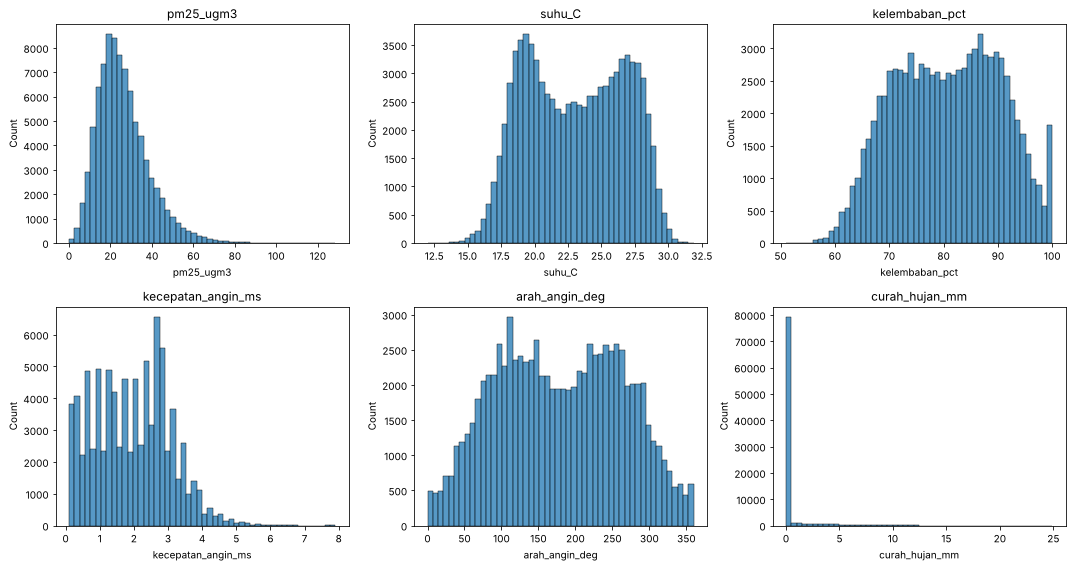

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
kolom_angka = ["pm25_ugm3", "suhu_C", "kelembaban_pct", "kecepatan_angin_ms", "arah_angin_deg", "curah_hujan_mm"]
for ax, kolom in zip(axes.flatten(), kolom_angka):
    sns.histplot(df.loc[df[kolom] != -999, kolom], bins=50, ax=ax)
    ax.set_title(kolom)
plt.tight_layout()
plt.show()

**Pembahasan.** Masalah yang ditemukan:

1. Nilai kosong sedikit: 144 baris (0,16%) di PM2.5, suhu, dan kelembapan, serta 877 baris (1%) di kecepatan angin.
2. Ada 398 baris yang persis sama.
3. Ada 173 nilai -999 di PM2.5.
4. Ada 88 nilai PM2.5 tepat 0. Nilai ini lolos dari pengecekan nilai negatif, padahal udara kota hampir tidak mungkin bebas partikel.

Nilai 0 di curah hujan (tidak hujan) dan di arah angin (utara) wajar. Distribusi PM2.5 condong ke kanan, sebagian besar di 15-35 µg/m³.

### 2.1 Cek zona waktu

Suhu paling tinggi biasanya sekitar pukul 14-15 WIB. Kalau jam puncak suhu suatu stasiun jauh berbeda,
kemungkinan waktunya tidak dicatat dalam WIB.

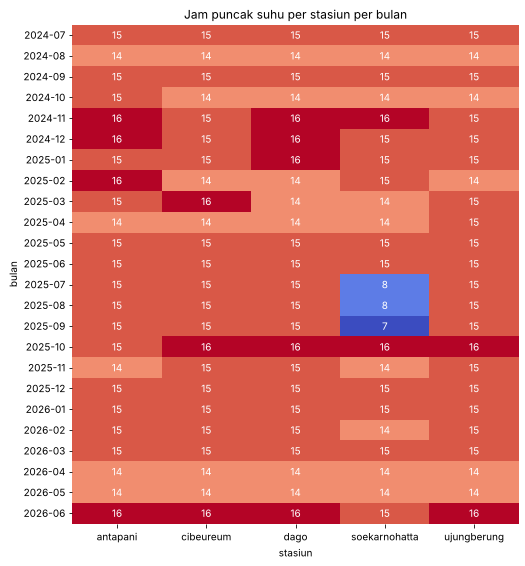

In [7]:
cek = df.copy()
cek["stasiun"] = cek["stasiun"].str.strip().str.lower().str.replace(" ", "").str.replace("-", "")
cek["stasiun"] = cek["stasiun"].replace({"soetta": "soekarnohatta"})
cek["waktu"] = pd.to_datetime(cek["waktu"])
cek["bulan"] = cek["waktu"].dt.strftime("%Y-%m")
cek["jam"] = cek["waktu"].dt.hour

suhu_per_jam = cek.groupby(["bulan", "stasiun", "jam"])["suhu_C"].mean().reset_index()
jam_puncak = suhu_per_jam.loc[suhu_per_jam.groupby(["bulan", "stasiun"])["suhu_C"].idxmax()]
tabel_puncak = jam_puncak.pivot(index="bulan", columns="stasiun", values="jam")

plt.figure(figsize=(8, 9))
sns.heatmap(tabel_puncak, annot=True, cmap="coolwarm", cbar=False)
plt.title("Jam puncak suhu per stasiun per bulan")
plt.show()

**Pembahasan.** Hampir semua stasiun punya jam puncak suhu di pukul 14-16. Hanya Soekarno-Hatta pada Juli, Agustus, dan September 2025 yang puncaknya di pukul 07-08, tepat 7 jam lebih awal. Selisih ini sama dengan selisih WIB dan UTC, jadi selama tiga bulan itu waktu Soekarno-Hatta dicatat dalam UTC.

Kesalahan ini juga membuat ada jam yang tercatat dua kali pada 2025-06-30 pukul 17:00-23:00. Kalau tidak diperbaiki, fitur jam, lag, dan target di stasiun ini bergeser 7 jam selama tiga bulan.

## 3. Pembersihan data

In [8]:
df_clean = df.copy()

# 1. Satukan nama stasiun
nama = df_clean["stasiun"].str.strip().str.lower().str.replace(" ", "").str.replace("-", "")
df_clean["stasiun"] = nama.map({
    "dago": "Dago", "soekarnohatta": "Soekarno-Hatta", "soetta": "Soekarno-Hatta",
    "cibeureum": "Cibeureum", "antapani": "Antapani", "ujungberung": "Ujungberung",
})
print("nama stasiun yang belum dikenali:", df_clean["stasiun"].isna().sum())

# 2. Ubah waktu ke datetime dan hapus baris yang persis sama
df_clean["waktu"] = pd.to_datetime(df_clean["waktu"])
n_duplikat = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print("duplikat dihapus:", n_duplikat)

nama stasiun yang belum dikenali: 0
duplikat dihapus: 398


### 3.1 Koreksi waktu UTC di Soekarno-Hatta

Dalam urutan baris asli file, waktu Soekarno-Hatta sempat mundur dari 2025-06-30 23:00 ke 2025-06-30 17:00.
Mulai titik itu waktunya dicatat dalam UTC, sampai baris 2025-09-30 16:00. Sesudahnya data kembali ke WIB
(2025-10-01 00:00). Baris di periode ini digeser +7 jam, tidak dibuang.

In [9]:
sh = df_clean[df_clean["stasiun"] == "Soekarno-Hatta"]
awal = sh.index[sh["waktu"].diff() < pd.Timedelta(0)][0]      # baris pertama saat waktu mundur
akhir = sh.index[sh["waktu"] == "2025-09-30 16:00"][-1]       # baris terakhir yang masih UTC

periode_utc = (df_clean["stasiun"] == "Soekarno-Hatta") & (df_clean.index >= awal) & (df_clean.index <= akhir)
df_clean.loc[periode_utc, "waktu"] += pd.Timedelta(hours=7)

print("baris yang digeser:", periode_utc.sum())
print("waktu ganda setelah koreksi:", df_clean.duplicated(["waktu", "stasiun"]).sum())

baris yang digeser: 2196
waktu ganda setelah koreksi: 0


In [10]:
# Bukti: jam puncak suhu Soekarno-Hatta sesudah koreksi
sesudah = df_clean[df_clean["stasiun"] == "Soekarno-Hatta"].copy()
sesudah["bulan"] = sesudah["waktu"].dt.strftime("%Y-%m")
sesudah["jam"] = sesudah["waktu"].dt.hour
rata = sesudah.groupby(["bulan", "jam"])["suhu_C"].mean().reset_index()
pd.DataFrame({
    "sebelum": tabel_puncak["soekarnohatta"],
    "sesudah": rata.loc[rata.groupby("bulan")["suhu_C"].idxmax()].set_index("bulan")["jam"],
}).loc["2025-05":"2025-11"]

,sebelum,sesudah
bulan,,
2025-05,15,15
2025-06,15,15
2025-07,8,15
2025-08,8,15
2025-09,7,14
2025-10,16,16
2025-11,14,14


### 3.2 Nilai PM2.5 yang tidak wajar

In [11]:
# Lihat nilai di sekitar PM2.5 = 0
urut = df_clean.sort_values(["stasiun", "waktu"])
sebelum = urut.groupby("stasiun")["pm25_ugm3"].shift(1)
sesudah = urut.groupby("stasiun")["pm25_ugm3"].shift(-1)
nol = urut["pm25_ugm3"] == 0
pd.DataFrame({"waktu": urut["waktu"], "stasiun": urut["stasiun"], "sebelum": sebelum, "nilai": 0.0,
              "sesudah": sesudah})[nol].head()

,waktu,stasiun,sebelum,nilai,sesudah
53513,2024-08-09 00:00:00,Antapani,23.4,0.0,34.0
54206,2024-09-06 21:00:00,Antapani,38.5,0.0,44.0
55489,2024-10-30 04:00:00,Antapani,26.9,0.0,35.1
55651,2024-11-05 23:00:00,Antapani,23.9,0.0,26.6
55772,2024-11-11 00:00:00,Antapani,6.5,0.0,10.9


In [12]:
n_sentinel = (df_clean["pm25_ugm3"] == -999).sum()
n_nol = (df_clean["pm25_ugm3"] == 0).sum()
df_clean.loc[df_clean["pm25_ugm3"].isin([-999, 0]), "pm25_ugm3"] = np.nan

df_clean = df_clean.sort_values(["stasiun", "waktu"]).reset_index(drop=True)
print("-999 diubah ke NaN:", n_sentinel)
print("0 diubah ke NaN   :", n_nol)
print("waktu ganda       :", df_clean.duplicated(["waktu", "stasiun"]).sum())
print("ukuran akhir      :", df_clean.shape)

-999 diubah ke NaN: 172
0 diubah ke NaN   : 87
waktu ganda       : 0
ukuran akhir      : (87252, 8)


In [13]:
# Cek rentang nilai cuaca
print(df_clean.describe().loc[["min", "max"]].round(1))

# Jam yang hilang per stasiun
for stasiun, g in df_clean.groupby("stasiun"):
    semua_jam = pd.date_range(g["waktu"].min(), g["waktu"].max(), freq="h")
    print(stasiun, "jam hilang:", len(semua_jam) - len(g))

                   waktu  pm25_ugm3  suhu_C  kelembaban_pct  kecepatan_angin_ms  arah_angin_deg  curah_hujan_mm
min  2024-07-01 00:00:00        1.0    12.0            51.0                 0.1             0.0             0.0
max  2026-06-30 23:00:00      128.4    31.9           100.0                 7.9           360.0            24.9
Antapani jam hilang: 64
Cibeureum jam hilang: 77
Dago jam hilang: 65
Soekarno-Hatta jam hilang: 76
Ujungberung jam hilang: 66


### 3.3 Ringkasan masalah data

In [14]:
pd.DataFrame([
    ["Nama stasiun tidak baku", (~df["stasiun"].isin(STASIUN)).sum(), "disatukan ke 5 nama"],
    ["Baris duplikat", n_duplikat, "dihapus"],
    ["Waktu Soekarno-Hatta Jul-Sep 2025 dalam UTC", periode_utc.sum(), "digeser +7 jam"],
    ["PM2.5 = -999", n_sentinel, "diubah ke NaN"],
    ["PM2.5 = 0", n_nol, "diubah ke NaN"],
    ["Kecepatan angin kosong", df_clean["kecepatan_angin_ms"].isna().sum(), "dibiarkan, diisi saat membuat fitur"],
], columns=["masalah", "jumlah baris", "penanganan"])

,masalah,jumlah baris,penanganan
0,Nama stasiun tidak baku,2635,disatukan ke 5 nama
1,Baris duplikat,398,dihapus
2,Waktu Soekarno-Hatta Jul-Sep 2025 dalam UTC,2196,digeser +7 jam
3,PM2.5 = -999,172,diubah ke NaN
4,PM2.5 = 0,87,diubah ke NaN
5,Kecepatan angin kosong,875,"dibiarkan, diisi saat membuat fitur"


In [15]:
Path("data").mkdir(exist_ok=True)
df_clean.to_csv("data/clean.csv", index=False)
print("tersimpan: data/clean.csv")

tersimpan: data/clean.csv


## 4. Distribusi PM2.5

In [16]:
eda = df_clean.copy()
eda["jam"] = eda["waktu"].dt.hour
eda["bulan"] = eda["waktu"].dt.month
eda["hari"] = eda["waktu"].dt.dayofweek   # 0 = Senin

eda.groupby("stasiun")["pm25_ugm3"].agg(
    rata_rata="mean", median="median", maks="max",
    persen_di_atas_55=lambda x: (x > 55).mean() * 100,
).loc[STASIUN].round(2)

,rata_rata,median,maks,persen_di_atas_55
stasiun,,,,
Dago,18.87,18.0,59.8,0.04
Soekarno-Hatta,34.59,32.8,128.4,9.30
Cibeureum,28.58,27.1,95.1,2.87
Antapani,25.28,24.0,86.2,1.23
Ujungberung,22.94,22.1,78.0,0.37


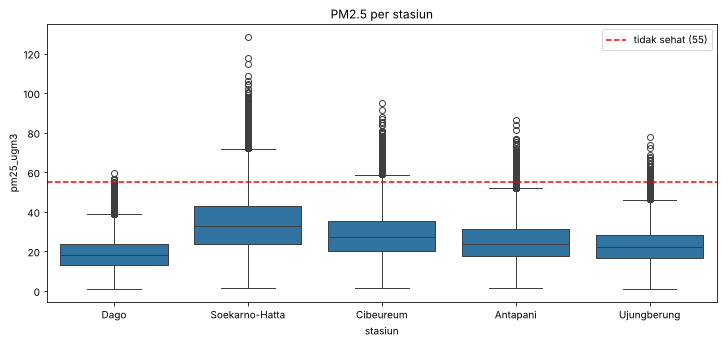

In [17]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=eda, x="stasiun", y="pm25_ugm3", order=STASIUN)
plt.axhline(55, color="red", linestyle="--", label="tidak sehat (55)")
plt.legend()
plt.title("PM2.5 per stasiun")
plt.show()

**Pembahasan.** Setelah dibersihkan, PM2.5 berkisar 1-128 µg/m³ dengan median sekitar 24 µg/m³. Soekarno-Hatta paling tercemar (rata-rata 34,6 µg/m³, 9,3% jam di atas 55). Dago paling bersih (rata-rata 18,9 µg/m³, hampir tidak pernah di atas 55). Karena perbedaannya besar, stasiun perlu menjadi fitur.

## 5. Pola waktu

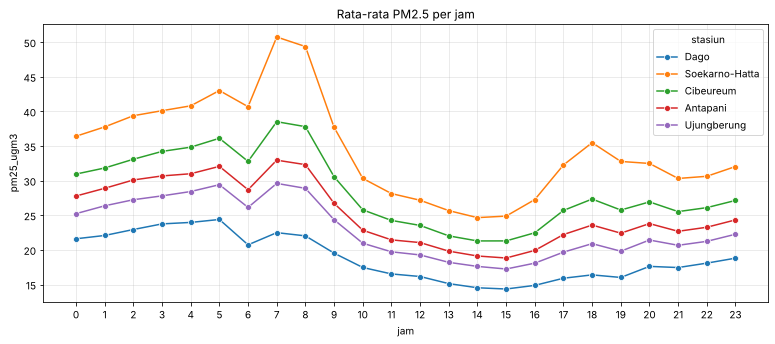

In [18]:
plt.figure(figsize=(13, 5))
sns.lineplot(data=eda, x="jam", y="pm25_ugm3", hue="stasiun", hue_order=STASIUN, errorbar=None, marker="o")
plt.xticks(range(24))
plt.title("Rata-rata PM2.5 per jam")
plt.grid(alpha=0.3)
plt.show()

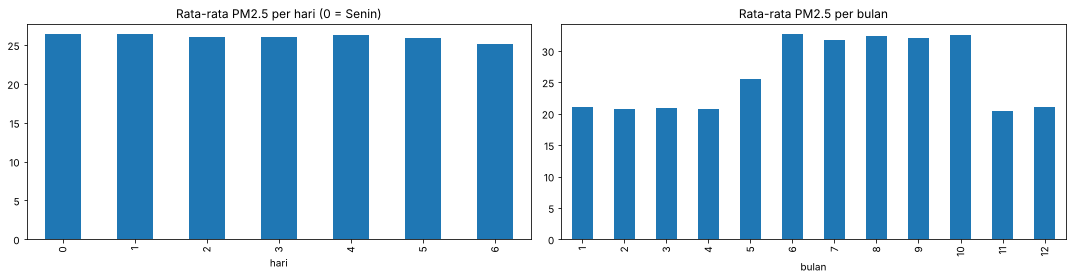

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
eda.groupby("hari")["pm25_ugm3"].mean().plot.bar(ax=axes[0], title="Rata-rata PM2.5 per hari (0 = Senin)")
eda.groupby("bulan")["pm25_ugm3"].mean().plot.bar(ax=axes[1], title="Rata-rata PM2.5 per bulan")
plt.tight_layout()
plt.show()

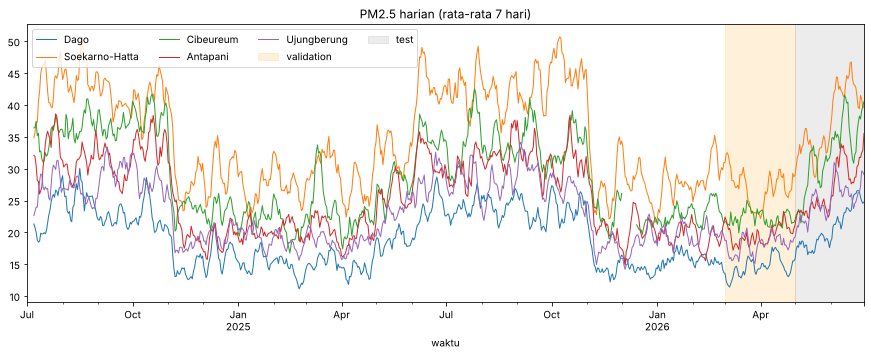

In [20]:
harian = eda.groupby([eda["waktu"].dt.date, "stasiun"])["pm25_ugm3"].mean().unstack()
harian.index = pd.to_datetime(harian.index)
harian[STASIUN].rolling(7).mean().plot(figsize=(15, 5), linewidth=1)
plt.axvspan("2026-03-01", "2026-05-01", color="orange", alpha=0.15, label="validation")
plt.axvspan("2026-05-01", "2026-07-01", color="grey", alpha=0.15, label="test")
plt.title("PM2.5 harian (rata-rata 7 hari)")
plt.legend(ncol=4)
plt.show()

**Pembahasan.** Ada tiga pola waktu:

- **Harian.** PM2.5 paling tinggi sekitar pukul 07, paling rendah sekitar pukul 14-15, lalu naik lagi pukul 19-20. Pola ini sama di semua stasiun, jadi jam penting sebagai fitur.
- **Musiman.** Juni-Oktober (kemarau) rata-ratanya sekitar 32 µg/m³, November-April sekitar 21 µg/m³. Data validation (Maret-April) ada di musim bersih, sedangkan data test (Mei-Juni) di awal kemarau. Hasil di validation bisa berbeda dengan test.
- **Mingguan.** Lemah. Hari Minggu hanya sekitar 1 µg/m³ lebih rendah.

## 6. Hubungan dengan cuaca

rata-rata PM2.5 saat hujan      : 15.3
rata-rata PM2.5 saat tidak hujan: 27.3


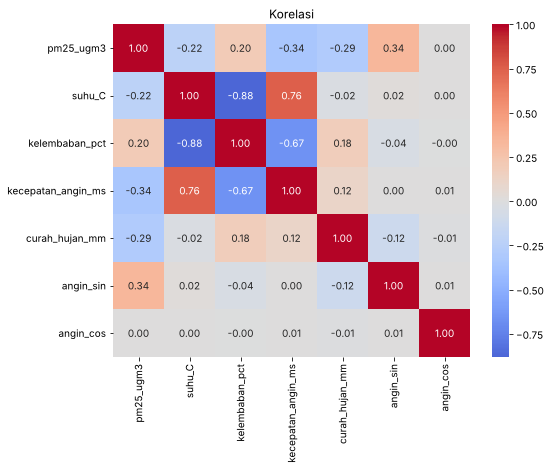

In [21]:
eda["angin_sin"] = np.sin(np.deg2rad(eda["arah_angin_deg"]))
eda["angin_cos"] = np.cos(np.deg2rad(eda["arah_angin_deg"]))
kolom = ["pm25_ugm3", "suhu_C", "kelembaban_pct", "kecepatan_angin_ms", "curah_hujan_mm", "angin_sin", "angin_cos"]

plt.figure(figsize=(8, 6))
sns.heatmap(eda[kolom].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi")
plt.show()

hujan = eda["curah_hujan_mm"] > 0
print("rata-rata PM2.5 saat hujan      :", round(eda.loc[hujan, "pm25_ugm3"].mean(), 1))
print("rata-rata PM2.5 saat tidak hujan:", round(eda.loc[~hujan, "pm25_ugm3"].mean(), 1))

**Pembahasan.** PM2.5 turun saat angin kencang (korelasi -0,34) dan saat hujan (-0,29). Rata-rata PM2.5 saat hujan 15,3 µg/m³, saat tidak hujan 27,3 µg/m³. Korelasi suhu (-0,22) dan kelembapan (+0,20) sebagian besar ikut pola harian.

Arah angin diubah ke sin dan cos agar 1° dan 359° dianggap berdekatan. Komponen `angin_sin` berkorelasi +0,34, artinya angin dari timur cenderung membawa PM2.5 lebih tinggi.

## 7. Autokorelasi

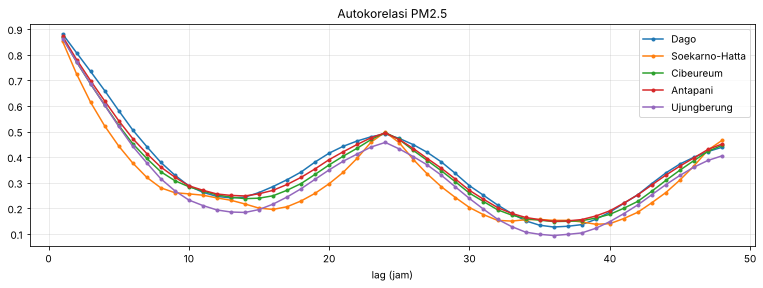

,Antapani,Cibeureum,Dago,Soekarno-Hatta,Ujungberung
1,0.87,0.87,0.88,0.85,0.86
3,0.70,0.69,0.73,0.61,0.69
12,0.26,0.25,0.25,0.24,0.19
24,0.49,0.50,0.49,0.50,0.46


In [22]:
# asfreq("h") mengisi jam yang hilang dengan NaN, jadi lag k selalu berarti k jam
autokorelasi = {}
for stasiun, g in eda.groupby("stasiun"):
    seri = g.set_index("waktu")["pm25_ugm3"].asfreq("h")
    autokorelasi[stasiun] = [seri.autocorr(lag) for lag in range(1, 49)]
autokorelasi = pd.DataFrame(autokorelasi, index=range(1, 49))

autokorelasi[STASIUN].plot(figsize=(13, 4), marker=".")
plt.xlabel("lag (jam)")
plt.title("Autokorelasi PM2.5")
plt.grid(alpha=0.3)
plt.show()

autokorelasi.loc[[1, 3, 12, 24]].round(2)

**Pembahasan.** Autokorelasi di lag 1 jam sekitar 0,85-0,88 dan di lag 3 jam sekitar 0,61-0,74. Ini sebabnya baseline persistence sudah cukup kuat. Autokorelasi naik lagi ke sekitar 0,5 di lag 24 jam, lebih tinggi dari lag 12 jam. Artinya nilai kemarin di jam yang sama ikut membantu. Soekarno-Hatta punya autokorelasi lag 3 paling rendah (0,61), jadi stasiun ini paling sulit diprediksi.

Kandidat fitur: PM2.5 jam ini dan beberapa jam lalu, PM2.5 24 jam lalu, cuaca saat ini, jam, bulan, dan stasiun.

## 8. Target, pembagian data, dan baseline

Target adalah PM2.5 pada jam `waktu + 3 jam` di stasiun yang sama. Kalau jam itu tidak ada atau PM2.5-nya
kosong, baris tersebut tidak dipakai.

In [23]:
target = df_clean[["waktu", "stasiun", "pm25_ugm3"]].rename(columns={"waktu": "target_time", "pm25_ugm3": "target_pm25"})
data = df_clean.assign(target_time=df_clean["waktu"] + pd.Timedelta(hours=3))
data = data.merge(target, on=["target_time", "stasiun"], how="left").dropna(subset=["target_pm25"])

train = data[data["target_time"] < "2026-03-01"]
val = data[(data["target_time"] >= "2026-03-01") & (data["target_time"] < "2026-05-01")]
test = data[data["target_time"] >= "2026-05-01"]
print("train:", len(train), "| validation:", len(val), "| test:", len(test))

train: 71988 | validation: 7258 | test: 7244


In [24]:
def nilai_baseline(bagian):
    """Persistence: PM2.5 tiga jam lagi dianggap sama dengan sekarang."""
    bagian = bagian.dropna(subset=["pm25_ugm3"])
    y, prediksi = bagian["target_pm25"], bagian["pm25_ugm3"]
    aktual_tinggi = y > 55
    return {
        "MAE": (y - prediksi).abs().mean(),
        "jam_di_atas_55": aktual_tinggi.sum(),
        "recall_55": (aktual_tinggi & (prediksi > 55)).sum() / aktual_tinggi.sum(),
    }

# Data test tidak dievaluasi di sini
pd.DataFrame({"train": nilai_baseline(train), "validation": nilai_baseline(val)}).T.round(3)

,MAE,jam_di_atas_55,recall_55
train,6.816,2113.0,0.356
validation,6.235,43.0,0.186


**Pembahasan.** Baseline persistence menghasilkan MAE 6,23 µg/m³ di validation dan 6,82 di train. Model final harus lebih kecil dari angka ini.

Persistence hanya memperingatkan 18,6% jam tidak sehat di validation, karena peringatan baru muncul saat udara sudah buruk. Data validation hanya punya 43 jam di atas 55, jadi angka recall ini mudah berubah.

## 9. Ringkasan

Langkah pembersihan:

- Nama stasiun disatukan.
- 398 baris duplikat dihapus.
- 2.196 baris Soekarno-Hatta yang tercatat dalam UTC digeser +7 jam.
- Nilai -999 dan 0 di PM2.5 diubah menjadi NaN.
- Jam yang hilang tidak diinterpolasi.

Hasilnya disimpan di `data/clean.csv` (87.252 baris).

Temuan yang paling berpengaruh untuk model:

1. Pola harian yang kuat, dengan puncak pukul 07 dan titik rendah pukul 14-15.
2. Perbedaan besar antarstasiun. Soekarno-Hatta hampir dua kali Dago.
3. Musim kemarau jauh lebih tercemar, sedangkan data validation ada di musim bersih.

Baseline persistence: MAE validation 6,23 µg/m³, recall >55 sebesar 18,6%.

Langkah berikutnya ada di `02_modeling.ipynb`.